# The dependence band shown with every aggregate, and an honest replication verdict

**Question:** What does a reader miss when an aggregate capital figure is shown without its dependence band, and does every
aggregate that Contraste commits carry the whole band?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 01 to 03 and 08 of this topic (the band, its bounds and the published practice)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state the claim, that every aggregate capital figure is shown with the whole band and only the simple sum is labelled
  capital, and check its structure on every committed aggregate;
- say why the six aggregates of five documents are really two, and run the engine's bracket and sign tests on each;
- see the engine return a whole band, never a scalar, on its own golden example;
- measure what each single figure of the band would have hidden, with the distance to the rest of the band and with the
  model-risk measures of the engine;
- read the records that say the replication of the supervisory models, case C19, stays planned.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import hashlib
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import band as rv_band
from riskvalidation.aggregation import bounds
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads every aggregate that **C18** commits, and the records that say what is and is not built.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** the four scenario documents `data/derived/C18/baseline.json`, `eba-2025-adverse.json`, `fed-2026-severely-adverse.json` and `ngfs-delayed-transition.json` and the aggregation document `t-copula-baseline.json` (each carries `outputs.aggregation`, and the last also the market-credit stress), the case index `data/derived/manifests/index.json`, the readiness record `data/derived/readiness.json`, and the engine's stress contract `docs/contracts/engine/stress-api.md` (its scope paragraph records why case C19 stays planned).
- **What is claimed and what is not.** The claim is about what **Contraste does**: it shows the band. It is not a claim that nobody else does, which the research could not establish beyond its own search.

In [2]:
# The aggregation block of each committed document, and the same block under the market-credit 0.8 stress
SCENARIOS = ("baseline", "eba-2025-adverse", "fed-2026-severely-adverse", "ngfs-delayed-transition")
blocks = {name: read_json(f"C18/{name}.json")["outputs"]["aggregation"] for name in SCENARIOS}
second = read_json("C18/t-copula-baseline.json")["outputs"]
STRESSED = "t-copula-baseline, market-credit 0.8"
blocks["t-copula-baseline"] = second["aggregation"]
blocks[STRESSED] = second["correlation_stress"]["aggregation"]
LIGHT = {"green": "green", "amber": "amber", "red": "red"}
NAMES = {"lower-bound": "lower bound", "simple-sum": "simple sum",
         "variance-covariance": "variance-covariance", "gaussian-copula": "Gaussian copula",
         "t-copula": "t copula", "worst-case": "worst case"}
print("documents with an aggregate", len(blocks))

documents with an aggregate 6


## Method

### Step 1: the claim, checked on every aggregate

**The claim.** Every aggregate capital figure of C18 is shown with the **band** of aggregation methods over the same marginals, one horizon and one confidence level: the lower bound, the simple sum, the square-root rule, the Gaussian copula, one t copula for each degree of freedom of the named set, and the sharp worst case by the rearrangement algorithm, in that order. The simple sum is the only row labelled **headline capital**; every other row, the Euler allocation and the model-risk measures are labelled **information, not capital**. The case never shows one diversified number.

The next cell checks that claim on every aggregate: the number and order of the rows, the status of each, that exactly one row
is the headline and it is the simple sum, the Euler additivity gap and the model-risk label. It also hashes the six blocks to
show which of them are one and the same.

In [3]:
# The structure of the band in every committed aggregate, and the hash of each block
EXPECTED = ["lower-bound", "simple-sum", "variance-covariance", "gaussian-copula", "t-copula", "t-copula", "t-copula",
            "worst-case"]
for name, block in blocks.items():
    methods = [row["method"] for row in block["band"]]
    headline = [row["method"] for row in block["band"] if row["status"] == "headline-capital"]
    others = sorted({row["status"] for row in block["band"] if row["method"] != "simple-sum"})
    gap = block["euler"]["additivity"]["relative_error"]
    print(f"{name:38s} rows {len(methods)} order as stated {methods == EXPECTED} {headline} {others}")
    print(f"{'':38s} Euler gap {gap:.1e} model risk {block['model_risk']['status']}",
          block["confidence_level"], block["horizon_years"])
dump = {name: json.dumps(block, sort_keys=True).encode("utf-8") for name, block in blocks.items()}
digest = {name: hashlib.sha256(raw).hexdigest() for name, raw in dump.items()}
same = [name for name in blocks if digest[name] == digest["baseline"]]
print("blocks identical to the baseline one", same)
print("distinct aggregates among the six", len(set(digest.values())))

baseline                               rows 8 order as stated True ['simple-sum'] ['information-not-capital']
                                       Euler gap 1.6e-16 model risk information-not-capital 0.999 1
eba-2025-adverse                       rows 8 order as stated True ['simple-sum'] ['information-not-capital']
                                       Euler gap 1.6e-16 model risk information-not-capital 0.999 1
fed-2026-severely-adverse              rows 8 order as stated True ['simple-sum'] ['information-not-capital']
                                       Euler gap 1.6e-16 model risk information-not-capital 0.999 1
ngfs-delayed-transition                rows 8 order as stated True ['simple-sum'] ['information-not-capital']
                                       Euler gap 1.6e-16 model risk information-not-capital 0.999 1
t-copula-baseline                      rows 8 order as stated True ['simple-sum'] ['information-not-capital']
                                       Euler gap 1

### Step 2: recomputing what can be recomputed, on every aggregate

Structure is not enough: the rows must be right. Two rows of the band depend only on the marginals' capitals and the correlation matrix, so the engine recomputes them exactly from each document: the simple sum and the square-root rule. The rules that bind the rest are the engine's tests: `worst_case_bracket` (every row inside the bracket) and `diversification_sign` (no diversified row above the simple sum), and the stressed document must have a larger square-root row than the base one, because a higher correlation cannot lower the capital.

The next cell recomputes those two rows with the engine on each of the six aggregates and reports whether they are the
committed ones, the only reproduction check of this notebook.

In [4]:
# Recompute the two closed-form rows of each aggregate with the engine
exact = {}
for name, block in blocks.items():
    ec = np.array([m["ec_clp_m"] for m in block["marginals"]])
    corr = np.array(block["correlation"]["matrix"])
    rows = {(r["method"], r["nu"]): r["capital_clp_m"] for r in block["band"]}
    exact[name] = np.isclose(simple.simple_sum(ec), rows[("simple-sum", None)])
    exact[name] = exact[name] and np.isclose(simple.variance_covariance(ec, corr), rows[("variance-covariance", None)])
    print(f"{name:38s} {bool(exact[name])}")

baseline                               True
eba-2025-adverse                       True
fed-2026-severely-adverse              True
ngfs-delayed-transition                True
t-copula-baseline                      True
t-copula-baseline, market-credit 0.8   True


The next cell runs the engine's `worst_case_bracket` and `diversification_sign` tests on each of the six aggregates and prints
the light of each.

In [5]:
# The bracket test and the sign test on each aggregate
kinds = ("variance-covariance", "gaussian-copula", "t-copula")
for name, block in blocks.items():
    rows = {(r["method"], r["nu"]): r["capital_clp_m"] for r in block["band"]}
    between = [v for (method, nu), v in rows.items() if method not in ("lower-bound", "worst-case")]
    bracket = agg_tests.worst_case_bracket(rows[("lower-bound", None)], between, rows[("worst-case", None)])
    factors = [r["diversification_factor"] for r in block["band"] if r["method"] in kinds]
    sign = agg_tests.diversification_sign(factors)
    print(f"{name:38s} {LIGHT[bracket.light.value]:6s} {LIGHT[sign.light.value]}")

baseline                               green  green
eba-2025-adverse                       green  green
fed-2026-severely-adverse              green  green
ngfs-delayed-transition                green  green
t-copula-baseline                      green  green
t-copula-baseline, market-credit 0.8   green  green


The next cell draws the band of the two distinct aggregates side by side, the base aggregate and the one with the market-credit
correlation raised to 0.8, with the headline marked.

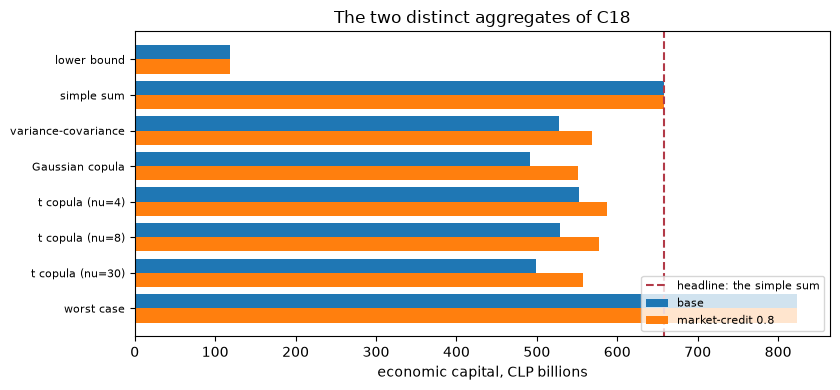

square-root row, base and stressed 528106.3 568520.5


In [6]:
# The band of the two distinct aggregates, base and stressed, with the headline marked
pair = {"base": blocks["baseline"], "market-credit 0.8": blocks[STRESSED]}
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(EXPECTED))[::-1]
for k, (label, block) in enumerate(pair.items()):
    ax.barh(y + (0.2 if k == 0 else -0.2), [r["capital_clp_m"] / 1e3 for r in block["band"]], height=0.4, label=label)
ax.axvline(blocks["baseline"]["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--",
           label="headline: the simple sum")
rows = blocks["baseline"]["band"]
ax.set_yticks(y)
ax.set_yticklabels([NAMES[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in rows], fontsize=8)
ax.set_xlabel("economic capital, CLP billions")
ax.set_title("The two distinct aggregates of C18")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
vc = {name: next(r["capital_clp_m"] for r in blocks[name]["band"] if r["method"] == "variance-covariance")
      for name in ("t-copula-baseline", STRESSED)}
base_vc, stress_vc = vc["t-copula-baseline"], vc[STRESSED]
print("square-root row, base and stressed", round(base_vc, 1), round(stress_vc, 1))

The six blocks are two aggregates. The aggregation does not depend on the scenario, so the baseline, EBA, Federal Reserve,
NGFS and t-copula documents carry the same block, with the same hash, and the sixth is that block under the market-credit
stress. Each has eight rows in the stated order, one headline row that is the simple sum, CLP 658,046 million in both, and
seven rows labelled information, one horizon and one level, an Euler gap of 1.6e-16, and a model-risk block labelled
information. The closed-form rows are recomputed exactly in all six, both tests are green in all six, and the stressed
square-root row, 568,521, is above the base one, 528,106. It does not follow that the band was checked under four stress
scenarios: it was checked on the base aggregate and on the market-credit stress.

### Step 3: the engine returns the whole band

The claim rests on the engine: `dependence_band` returns a `Band` of rows and a headline, never a scalar, and its docstring
gives a golden example: capitals 3 and 4, expected losses 0 and correlation 0.5, which must give a simple-sum row of 7.0 and a
square-root row of 6.0828, with the lower bound under the square-root row and the worst case above it. The next cell builds two
normal marginals with those 99.9 percent capitals, runs `dependence_band` at a reduced size (200,000 draws, 20,000 bound
cells), prints the rows with their status and draws them.

returned object, headline, rows Band 7.0 7
lower bound                    0.7601  0.1086 information-not-capital
simple sum                     7.0000  1.0000 headline-capital
variance-covariance            6.0828  0.8690 information-not-capital
Gaussian copula                6.0912  0.8702 information-not-capital
t copula (nu=4)                6.4726  0.9247 information-not-capital
t copula (nu=30)               6.2208  0.8887 information-not-capital
worst case                     7.4467  1.0638 information-not-capital


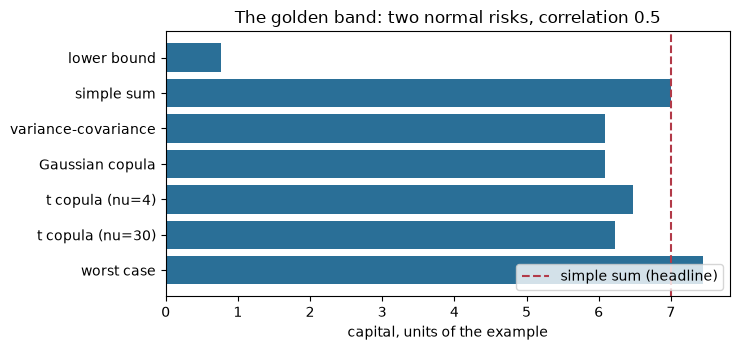

In [7]:
# The engine's golden example: two normal marginals with capitals 3 and 4, and the whole band it returns
z = stats.norm.ppf(0.999)
normal_sample = stats.norm.ppf((np.arange(1, 100_001) - 0.5) / 100_000)
ppfs = [cop.marginal_ppf_sample(capital / z * normal_sample) for capital in (3.0, 4.0)]
golden = rv_band.dependence_band(ppfs, np.array([3.0, 4.0]), np.array([0.0, 0.0]), np.array([[1.0, 0.5], [0.5, 1.0]]),
                                 [4.0, 30.0], level=0.999, horizon_years=1, n_draws=200_000, seed=1,
                                 chunk_size=100_000, bounds_n=20_000, bounds_epsilon=1e-3,
                                 ec_consistency_tolerance=0.05)
print("returned object, headline, rows", type(golden).__name__, golden.headline, len(golden.rows))
labels = []
for row in golden.rows:
    labels.append(NAMES[row.method] + (f" (nu={row.nu:g})" if row.nu else ""))
    print(f"{labels[-1]:28s} {row.capital:8.4f} {row.diversification_factor:7.4f} {row.status}")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(labels[::-1], [r.capital for r in golden.rows][::-1], color="#2a6f97")
ax.axvline(golden.headline, color="#b23a48", linestyle="--", label="simple sum (headline)")
ax.set_xlabel("capital, units of the example")
ax.set_title("The golden band: two normal risks, correlation 0.5")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

The engine returns an object of the class `Band` with seven rows and a headline of 7.0, never a scalar. The square-root row is
6.0828, the golden value, the Gaussian copula 6.0912 and the t copulas 6.4726 and 6.2208, and the two bounds are 0.7601 and
7.4467, so the worst case is 1.0638 times the simple sum even for two risks of this size. Only the simple sum is labelled
headline capital. The ordering holds without the case's own data, which is what makes the claim a property of the engine and
not of one set of documents.

The band's two bounds come from the sharp VaR bounds of the engine. The next cell calls `worst_var_bounds` directly on the same
two marginals, with the same number of cells and tolerance, and prints the best and the worst VaR beside the two rows of the
band, so that the reader sees where those rows come from.

In [8]:
# The sharp VaR bounds of the two golden marginals, called directly, beside the two bound rows of the band
direct = bounds.worst_var_bounds(ppfs, 0.999, 20_000, 1e-3, seed=1)
capital_of = {row.method: row.capital for row in golden.rows}
print("best VaR range, direct", np.round(direct.lower_range, 4))
print("worst VaR range, direct", np.round(direct.upper_range, 4))
print("band rows: lower bound and worst case")
print(round(capital_of["lower-bound"], 4), round(capital_of["worst-case"], 4))

best VaR range, direct [0.7601 0.7719]
worst VaR range, direct [7.4466 7.4467]
band rows: lower bound and worst case
0.7601 7.4467


The direct call gives a best VaR between 0.7601 and 0.7719 and a worst VaR between 7.4466 and 7.4467, and the two rows of the
band are the ends of those ranges, 0.7601 and 7.4467, with no expected loss to subtract. So the two bounds of the band are not
a separate model: they are the engine's sharp bounds, the best and the worst VaR over every possible dependence, with the rows
of the copulas between them.

## Comparison

What the research found as the practice to go beyond (dossier 05, G.2 and G.3, with the status of each statement):

- The dossier **prescribes** the band, "instead of a single diversified number", and warns against claiming that diversification benefits are robust; this is a recommendation of the research, not a description of what supervisors or toolkits do.
- The Joint Forum found aggregation models "a work in progress" on which supervisors generally do not rely (the press release of 21 October 2010, https://www.bis.org/press/p101021.htm, gives both phrases).
- Rosenberg and Schuermann (2006) show, in one study, that the choice of copula matters modestly while the additive approximation overestimates risk by about 30 to 40 percent; and Embrechts, Puccetti and Rueschendorf (2013) give the sharp worst-case bounds, a method that exists in the literature.
- The research **found no maintained toolkit or published practice that ships the band beside every aggregate** (UNVERIFIED beyond the dossier's own search).

What exists, then, is the ingredients: the copulas, the bounds, the reference and the recommendation. What the case adds is to **compose them and never show one number alone**, as a rule enforced by contract (the case's requirements CT-1811 and CT-1812) and by the engine's return type.

In [9]:
# Read the requirements lines of the case that make the band a rule, to quote their identifiers and gates
path = ROOT / "docs" / "design" / "features" / "c18" / "requirements.md"
for line in path.read_text(encoding="utf-8").splitlines():
    if line.startswith("| CT-1811") or line.startswith("| CT-1812"):
        identifier, text, gate = [cell.strip() for cell in line.strip("|").split("|")[:3]]
        print(identifier, "the gate that fails when it is violated", gate.split("::")[-1].strip("` "))

CT-1811 the gate that fails when it is violated test_the_headline_is_the_simple_sum_and_every_other_figure_is_information
CT-1812 the gate that fails when it is violated test_the_band_has_the_ladder_rows_and_the_euler_allocation_adds_up


## Evidence

**The claim, the dependence band shown with every aggregate.** The steps above are its evidence: the band is in every committed aggregate, in a fixed order, with one headline row and the rest labelled information; its closed-form rows are recomputed exactly; its structural rules pass; its engine returns the whole band; and the requirements CT-1811 and CT-1812 make it a gated rule of the case. The claim is stated as far as the evidence goes: **the case shows the band, always**. That the literature has no equivalent is UNVERIFIED beyond the research's search.

What the band adds over a single number is measurable on the committed document.

The next cell takes the baseline band and, for each of three single figures, the headline alone, the Gaussian figure alone and
the worst case alone, computes its diversification factor and the Barrieu and Scandolo measures of the engine with that
figure as the reference. The figure draws the range that the other seven rows span, as a multiple of each single figure.

the headline alone (simple sum)          658,046 below, above 6, 1
                                       others as multiples of it 0.18 - 1.25
                                       FD 1.000 AM 0.251 RM 0.235
the Gaussian figure alone                491,974 below, above 1, 6
                                       others as multiples of it 0.24 - 1.67
                                       FD 0.748 AM 0.674 RM 0.470
the worst case alone                     823,332 below, above 7, 0
                                       others as multiples of it 0.14 - 0.80
                                       FD 1.251 AM 0.000 RM 0.000


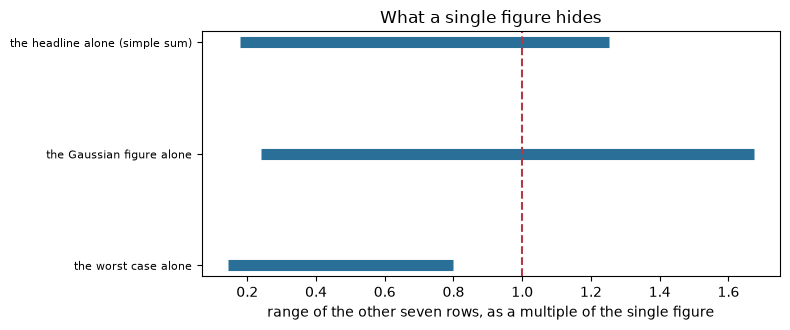

the band as shown, CLP millions 118,517.5 823,331.5


In [10]:
# What each single figure of the baseline aggregate would have said, and the share of the band it would have hidden
rows = {(r["method"], r["nu"]): r["capital_clp_m"] for r in blocks["baseline"]["band"]}
ec = np.array([m["ec_clp_m"] for m in blocks["baseline"]["marginals"]])
keys, capitals = list(rows), list(rows.values())
singles = (("the headline alone (simple sum)", ("simple-sum", None)),
           ("the Gaussian figure alone", ("gaussian-copula", None)),
           ("the worst case alone", ("worst-case", None)))
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, (label, key) in enumerate(singles):
    others = [v / rows[key] for kk, v in rows.items() if kk != key]
    measures = model_risk.barrieu_scandolo(capitals, keys.index(key))
    factor = simple.diversification_factor(rows[key], ec)
    ax.hlines(-k, min(others), max(others), color="#2a6f97", linewidth=8)
    print(f"{label:38s} {rows[key]:9,.0f} below, above {sum(o < 1 for o in others)}, {sum(o > 1 for o in others)}")
    print(f"{'':38s} others as multiples of it {min(others):.2f} - {max(others):.2f}")
    print(f"{'':38s} FD {factor:.3f} AM {measures.am:.3f} RM {measures.rm:.3f}")
ax.axvline(1.0, color="#b23a48", linestyle="--")
ax.set_yticks([0, -1, -2])
ax.set_yticklabels([label for label, _ in singles], fontsize=8)
ax.set_xlabel("range of the other seven rows, as a multiple of the single figure")
ax.set_title("What a single figure hides")
fig.tight_layout()
plt.show()
print("the band as shown, CLP millions", f"{min(capitals):,.1f}", f"{max(capitals):,.1f}")

Each single figure hides most of the band. The headline alone hides that the worst case is above it, 6 rows below and 1
above, and that the others run from 0.18 to 1.25 of it. The Gaussian figure alone has 1 row below and 6 above, and the others
run from 0.24 to 1.67 of it, with an add-on multiplier of 0.674 to reach the worst case. The worst case alone has all seven
others below, down to 0.14 of it. The three bars are three readers of the same document who would have come away with three
different pictures of the risk, and the band as a whole spans a factor of seven, from CLP 118,518 to 823,332 million. That
is a measure of the claim, not a count of rows.

## Results

The second part of this notebook is a statement about **what is not built**. The topic's cases are C18, built, and C19, the
replication of the supervisory stress models against published loss rates ("known answer"), which **stays planned**. This
notebook teaches nothing from C19. It reads the three records that say so: the case index lists C19 with a manifest path, the
readiness record says that path is missing and gives the reason, and the engine's stress contract records why: no Federal
Reserve portfolio type is replicable from the public record, so the engine has no supervisory replication function and no
supervisory replication test. The next cell reads the three records and prints what each says.

In [11]:
# Read the three records that say C19 is planned and not built
index = read_json("manifests/index.json")
c19 = next(case for case in index["cases"] if case["case_id"] == "C19")
print("C19", c19["kind"], c19["manifest_path"], (DERIVED / c19["manifest_path"]).exists())
readiness = next(c for c in read_json("readiness.json")["contracts"] if c["id"] == "case-manifest")
print("readiness record: state, missing", readiness["state"], readiness["missing"])
stress_text = (ROOT / "docs" / "contracts" / "engine" / "stress-api.md").read_text(encoding="utf-8")
contract_text = " ".join(stress_text.split())
keeps = "keeps C19 (supervisory stress model replication) planned" in contract_text
print("the stress contract keeps C19 planned", keeps)
none = "no supervisory function and no supervisory replication test" in contract_text
print("no supervisory replication function or test", none)
stress_cases = [case for case in index["cases"] if case["category_id"] == "capital-stress"]
built = sum((DERIVED / case["manifest_path"]).exists() for case in stress_cases)
print("capital-and-stress cases, with a manifest", len(stress_cases), built)

C19 real manifests/C19.json False
readiness record: state, missing partial ['manifests/C19.json']
the stress contract keeps C19 planned True
no supervisory replication function or test True
capital-and-stress cases, with a manifest 2 1


**Answer:** the claim holds on every committed aggregate, and a reader who saw one figure alone would have missed most of it.
The six aggregation blocks of five documents are two distinct aggregates, each with eight band rows in the stated order, one
headline row that is the simple sum, CLP 658,046 million, and seven rows labelled information; the closed-form rows are
recomputed exactly and the bracket and sign tests are green in all six. The band spans 118,517.5 to 823,331.5 million, a factor
of seven: the headline alone hides that the worst case is 1.25 times it, the Gaussian figure alone hides a range of 0.24 to
1.67 times itself, and the worst case alone hides that every other row is between 0.14 and 0.80 times it. The replication of
the supervisory stress models, C19, stays planned, and the three records agree: of the two capital-and-stress cases, one has a
manifest.

What this notebook does not claim: that no one else shows a band (UNVERIFIED beyond the research's search); that the band is
derived from first principles here (notebooks 02 and 03 rebuild the marginals from the committed quantile grids and get the
committed rows back to within 0.01 percent; the million-draw samples behind the grids are not committed); or anything about
C19's answer, which is not built.

## Summary

- The claim states that every aggregate capital figure of C18 is shown with the whole dependence band, with one headline row and the rest labelled information; the committed documents carry it in two distinct aggregates (the base one, repeated in five documents, and the market-credit 0.8 stress) and every check of this notebook passes.
- The closed-form rows of each band are recomputed exactly by the engine; the bracket and sign rules hold; the engine's `dependence_band` returns a `Band`, never a scalar, on its own golden example.
- The claim is limited to what the case does; that nobody else ships the band is UNVERIFIED beyond the research's search.
- A single figure hides most of the band: the headline alone hides that the worst case is above it, and the band as a whole spans a factor of seven.
- The replication of the supervisory stress models, C19, stays planned: the three records agree, and nothing in this topic teaches from it.

**What to try next.** Add the sharp bounds to a band of your own marginals with `dependence_band` and look at the width of your own band before you look at a diversified figure.

## References

- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation. https://www.bis.org/publ/joint25.pdf
- Bank for International Settlements (2010), press release of 21 October 2010 on the Joint Forum report Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Dossier 05 of the persisted Contraste research (G.2 and G.3: the evidence on aggregation and the dependence pitfalls), as summarised in the SDD's research basis.
- This repository: `docs/design/features/c18/requirements.md` (CT-1811 and CT-1812), `docs/contracts/engine/aggregation-api.md` and `docs/contracts/engine/stress-api.md`.